In [10]:
import torch 
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from torch.utils.tensorboard import SummaryWriter
from torch.functional import F
import sys

writer = SummaryWriter('runs/mnist')

In [2]:
import torch
import torch.backends
import torch.backends.mps

# device config
if torch.backends.mps.is_available(): 
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else: 
    device = torch.device("cpu")

device

device(type='mps')

In [3]:
# hyperparameters 
input_size = 784 # 28x28
hidden_size = 100
num_classes = 10 # 0-9 digits 
num_epochs = 2
batch_size = 100 
learning_rate = 0.001

# MNIST 
train_dataset = torchvision.datasets.MNIST(root="data", train=True, transform=transforms.ToTensor(), download=True)
test_dataset = torchvision.datasets.MNIST(root="data", train=False, transform=transforms.ToTensor())

In [4]:
import torch.utils
import torch.utils.data


train_loader = torch.utils.data.DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)

In [5]:
examples = iter(train_loader) 

samples, labels = examples._next_data()

# samples: 100 samples, 1 color channel, 28 x 28 image
# labels: 100 labels, each has a value between 0 and 9
samples.shape, labels.shape

(torch.Size([100, 1, 28, 28]), torch.Size([100]))

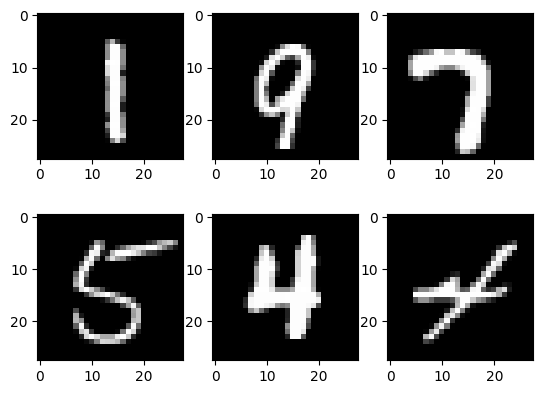

In [6]:
for i in range(6): 
    plt.subplot(2, 3, i+1)
    plt.imshow(samples[i][0], cmap="gray")

img_grid = torchvision.utils.make_grid(samples)
writer.add_image("mnist images", img_grid)

writer.close()

In [7]:
class NeuralNet(nn.Module): 
    def __init__(self, input_size, hidden_size, output_size):
        super(NeuralNet, self).__init__()
        self.l1 = nn.Linear(input_size, hidden_size) 
        self.relu = nn.ReLU()
        self.l2 = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out = self.l1(x)
        out = self.relu(out)
        out = self.l2(out)

        # no softmax, it will be included in the loss function
        return out
    
model = NeuralNet(input_size, hidden_size, num_classes).to(device)

# loss and optimizer 
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr = learning_rate) 

writer.add_graph(model, samples.reshape(-1, 28*28).to(device)) 
writer.close()


In [8]:

# training loop 
n_total_steps = len(train_loader) 

running_loss = 0.0
running_correct = 0

for epoch in range(num_epochs): 
    # iterate over a batch of data
    for i, (images, labels) in enumerate(train_loader): 
        # reshape images to fit input of 784
        # 100, 1, 28, 28 -> 100, 784
        images = images.reshape(-1, 28*28).to(device)
        labels = labels.to(device) 

        # forward pass 
        outputs = model(images) 
        loss = criterion(outputs, labels) 

        # backward pass
        optimizer.zero_grad()
        loss.backward()

        # update parameters (weights and biases)
        optimizer.step()

        # track loss and accuracy
        running_loss += loss.item()

        _, predicted = torch.max(outputs.data, 1) 
        running_correct += (predicted == labels).sum().item()

        if (i+1) % 100 == 0: 
            print(f"epoch {epoch+1} / {num_epochs}, step {i+1}/{n_total_steps}, loss = {loss.item():.4f}")

            # add to tensorboard, once every 100 steps
            writer.add_scalar("training loss", running_loss / 100, epoch * n_total_steps + i)
            writer.add_scalar("accuracy", running_correct / 100, epoch * n_total_steps + i)
            
            running_loss = 0.0
            running_correct = 0

writer.close()


epoch 1 / 2, step 100/600, loss = 0.4912
epoch 1 / 2, step 200/600, loss = 0.2162
epoch 1 / 2, step 300/600, loss = 0.2947
epoch 1 / 2, step 400/600, loss = 0.2649
epoch 1 / 2, step 500/600, loss = 0.1934
epoch 1 / 2, step 600/600, loss = 0.1866
epoch 2 / 2, step 100/600, loss = 0.2270
epoch 2 / 2, step 200/600, loss = 0.3507
epoch 2 / 2, step 300/600, loss = 0.0886
epoch 2 / 2, step 400/600, loss = 0.2531
epoch 2 / 2, step 500/600, loss = 0.1719
epoch 2 / 2, step 600/600, loss = 0.1202


In [13]:
# test -> precision recall curve
tb_labels = []
tb_preds = []

with torch.no_grad(): 
    n_correct = 0 
    n_samples = 0 
    for images, labels in test_loader: 
        images = images.reshape(-1, 28 * 28).to(device) 
        labels = labels.to(device) 
        outputs = model(images) 

        # value, index
        _, predictions = torch.max(outputs, 1) 
        n_samples += labels.shape[0]
        n_correct += (predictions == labels).sum().item()

        # calculate softmax for outputs

        class_predictions = [F.softmax(output, dim = 0) for output in outputs]

        # append to tensorboard lists
        tb_preds.append(class_predictions)
        tb_labels.append(predictions)

    # preds is 2 dim tensor, 10k x 10
    tb_preds = torch.cat([torch.stack(batch) for batch in tb_preds])

    # convert to tensor 1D tensor, 10k x 1
    tb_labels = torch.cat(tb_labels)

    classes = range(10) # digits 0-9

    for i in classes: 
        labels_i = tb_labels == i # 10k x 1, 1s where the label is i
        preds_i = tb_preds[:, i] # 10k x 1, vector of probabilities for class i 
        writer.add_pr_curve(str(i), labels_i, preds_i, global_step=0) # global step is 0, because we are not iterating over epochs
        writer.close()

    acc = 100.0 * n_correct / n_samples
    print(f"accuracy = {acc}")


accuracy = 95.12
